# Plasma solution simulation



## Functions

In [4]:
def initialise_ionosphere_region(df, region):
    """ takes a dataframe of ionospheric properties and pulls the associated properties for a given region. making the necessary calculations required to run simulation CURRENTLY NOT ABLE TO HANDLE GEO"""

    # Pulls property name and values into a list and numpy array respectively
    value = df_ionosphere[region].to_numpy()
    properties =  df_ionosphere["Properties"].to_list()

    # Creates a dictionary of the properties and values for the given region
    plasma_properties = dict(zip(properties, value))
    return plasma_properties

def normalised_plasma_potential(a, debye_length, mass_ratio, potential_radius = None):
    """Calculates the normalised plasma potential for a given debris radius, debye length, and mass ratio."""
    def eqn_surface_potential(x, mass_ratio, s, a):
        """Equation 32 from the NASA paper in the form 0 = f(x) where f(x) is equal to g(x) - A(1-B * e(Cx), this equation is then put through brents method to identify the roots of the function, eφ/kT"""
        return np.exp(x) - np.sqrt(mass_ratio) * (s/a)**2  * ( 1 - ((s**2 - a**2)/s**2) * np.exp( (a**2 / (s**2 - a**2)) * x ))

    # If potential_radius is not provided, it defaults to the debye_length.
    if potential_radius is None:
        potential_radius = debye_length

    s = a + debye_length

    x_sol = brentq(eqn_surface_potential, -10, 0, args=(mass_ratio, s, a))
    phi_np = x_sol * np.exp(-potential_radius/debye_length)  # normalised plasma potential

    return phi_np

def forcing_term_general(np_potential, xi, tau, vd, G):
    return np_potential * np.exp(-1 * ((xi - (vd * tau))/ G)**2)

def ck_solutions(last_sol, current_sol, alpha, beta, k, f, dt):
    """Use the Crank-Nicolson scheme to solve the normalised forced KdV equation on a non-periodic domain."""
    # pre-calculating coefficients
    _ck_beta = dt * beta * 1j * k**3 # removed s**3 term
    _ck_z = dt * 1j * k # removed s term

    # computing the rfft of u & f halfs the length of array which then is multipled by 1024 leng coefficents arrays because of k
    _ck_beta_fft = _ck_beta[:len(k)//2+1]  # Keep only first 513 elements
    _ck_z_fft = _ck_z[:len(k)//2+1]

    # Fourier transform of the last solution, current solution, and forcing term
    fft_last = rfft(last_sol)
    fft_current_sqrd = rfft(current_sol**2)
    fft_f = rfft(f)

    return irfft( ((1 - _ck_beta_fft)**-1) * ( (1 + _ck_beta_fft) * fft_last - alpha * _ck_z_fft * (fft_current_sqrd) + _ck_z_fft * fft_f ) )

## Imports & variables

In [5]:
import numpy as np
from numpy.fft import rfft, irfft
import pandas as pd
from numpy import pi, cos, linspace, arange
from scipy.fftpack import diff as psdiff
import pandas as pd
import matplotlib.pyplot as plt
from IPython.core.pylabtools import figsize
from scipy.optimize import brentq

# Upload the Ionosphere properties from the Excel file
df_ionosphere= pd.read_excel(r'Ionosphere prop.xltx')
display(df_ionosphere)

# Pulls the properties for the Low LEO region into a dictionary
plasma_prop = initialise_ionosphere_region(df_ionosphere, "Low LEO")

# =============================== Inputs ================================

# Global constants
__kb__ = 1.380649e-23  #Boltzmann constant in J/K
__c__ = 299792458.0  # Speed of light in m/s
__me__ = 9.1093837139e-31 # Electron mass in kg
__mh__ = 1.67262192595e-27 # Hydrogen ion aka proton mass in kg
__mo__ = 15.994914619 * 1.66053906892e-27 # Oxygen ion mass in kg

# Physical parameters
a = 0.01 # debris in m
alpha = 1.0051
beta = 0.4925

vd = 1.20 # Debris velocity in km/s
np_potential = None # Normalised plasma potential, if None, it will be automatically calculated.

# Simulation parameters
N = 1024 # number of discretised points in the domain (power of 2 for FFT speed)
L = 300.0 # size of the domain
G = a / (plasma_prop["Debye Length"] * 1e-2) # Normalised forcing width
dtau = 1e-4# TU
tau_inital = 0.0  # TU
tau_final = 60.0 # TU
num_stablising_steps = 5 # Number of steps to stablise the solution before starting the main simulation

# Normlaised units
TU = (plasma_prop["Debye Length"] * 1e-2) / (plasma_prop["Ion Acoustic Velocity"] * 1e3) # Time unit in seconds
vd_norm = vd / (plasma_prop["Ion Acoustic Velocity"] * 1e3) # Normalised debris velocity

# Determine the ion species and set the corresponding ion mass and mass ratio
if plasma_prop["Ion Species"] == "O":
    mi = __mo__
    mass_ratio = __me__ / __mo__
elif plasma_prop["Ion Species"] == "H":
    mi= __mh__
    mass_ratio = __me__ / __mh__
else:
    raise ValueError("Ion species not recognised. Please use 'O' for Oxygen or 'H' for Hydrogen.")

# if up
if np_potential is None:
    np_potential = normalised_plasma_potential(a, plasma_prop["Debye Length"], mass_ratio)

,Properties,Units,Low LEO,High LEO I,High LEO II,GEO
0,Altitude,km,700,1200,1400,35786
1,Latitude,deg,"0,50",0-55,0-55,0-90
2,Electron Density,cm^-3,200000,100000,10000,1
3,Electron Tempreture,eV,0.25,0.35,0.35,1000
4,Ion Species,NaN,O,H,H,OH
5,Ion Mass,proton mass,16,1,1,"16,1"
6,Debye Length,cm,0.83,1.38,4.36,23504
7,Debris Velocity Circular Orbit,km/s,7.51,7.26,7.16,3.08
8,Ion Acoustic Velocity,km/s,1.22,5.75,5.75,"77.43 , 309.73"


## Running the Simulation

In [12]:
def run_simulation(a, L, N, tau_inital, tau_final, dtau, alpha, beta, vd_norm, G, np_potential, analytical_sol, forcing_fn, num_stablising_steps=5, mode="rest"):
    """Runs the simulation for the normalised forced KdV equation using the Crank-Nicolson scheme. The simulation can be run in two modes: 'rest' for starting from rest frame, and 'analyitcal' starting from some exact solution for the kdv equation. The function returns the solution array, time array, and mesh space."""

    xi = np.linspace(-L, L , N, endpoint=False) # Defining mesh space & wave numbers
    dxi = xi[1] - xi[0]
    k = 2*np.pi*np.fft.fftfreq(N, d=dxi)

    if mode == "rest":
        num_steps = int(abs((tau_inital + (dtau/10) * num_stablising_steps ) - tau_final)/dtau) + num_stablising_steps + 2
    elif mode == "analytical":
        num_steps = int(abs(tau_inital - tau_final)/dtau) + 1
    else:
        raise ValueError("Invalid mode. Please choose 'rest' or 'analytical'.")

    # Initialising the solution array and time array
    time_array = np.zeros(num_steps)
    sol = np.zeros(((len(time_array) + 1),N))
    print(f"Number of time steps: {num_steps}")

    if mode == "rest":
        sol[0] = np.zeros(N) # Initial condition is set to 0
        sol[1] = np.zeros(N)
        time_array[0] = 0
        time_array[1] = tau_inital

    else: # mode == "analytical"
        sol[0] = analytical_sol(a, xi) # Initial condition is set to the exact solution of the KdV equation
        sol[1] = analytical_sol(a, xi)
        time_array[0] = -1 * dtau  # Intial time step is set to tau_inital - dtau to account for the first step being a special case
        time_array[1] = 0

    step = 1 # Start from the second time step since the first two are already set
    current_time = tau_inital   # start
    while current_time <= tau_final:
        current_dtau = dtau
        if mode == "rest" and step <= num_stablising_steps:
            current_dtau = dtau / 10

        forcing = forcing_fn(np_potential, xi, current_time, vd_norm, G)
        sol[step + 1] = ck_solutions(last_sol=sol[step - 1],  # Propogate exact solution forward in time with CK scheme
                                     current_sol=sol[step],
                                     alpha=alpha,
                                     beta=beta,
                                     k=k,
                                     f=forcing,
                                     dt=current_dtau
                                     )

        if step % 1000 == 0: # only prints every 10000 steps to avoid cluttering the output
            print(f"Time step: {step}, Time: {current_time:.2f} TU")
            print(f"Max value of solution: {np.max(sol[step + 1]):.4f}, Min value of solution: {np.min(sol[step + 1]):.4f}")

        time_array[step] = current_time
        step += 1
        current_time += current_dtau

    print("Simulation complete.")
    print(time_array[-1], sol[-1])
    return sol, time_array, xi


analytical_sol, analytical_time_array, xi= run_simulation( a, L, N, tau_inital, tau_final, dtau, alpha, beta, vd_norm, G, np_potential,fkdv_exact_solution, forcing_term_general, mode="analytical")
numerical_sol, numerical_time_array, _ = run_simulation(a, L, N, tau_inital, tau_final, dtau, alpha, beta, vd_norm, G, np_potential,fkdv_exact_solution, forcing_term_general, mode="rest")

Number of time steps: 3001
Time step: 1000, Time: 19.98 TU
Max value of solution: 2.0853, Min value of solution: -1.0556
Time step: 2000, Time: 39.98 TU
Max value of solution: 2.1110, Min value of solution: -1.1084
Time step: 3000, Time: 59.98 TU
Max value of solution: 2.1516, Min value of solution: -1.1018
Simulation complete.
59.98000000000378 [ 0.01180862  0.00261525 -0.0092763  ... -0.01164513 -0.0039599
  0.00822935]
Number of time steps: 3006
Time step: 1000, Time: 19.89 TU
Max value of solution: 2.0755, Min value of solution: -1.0536
Time step: 2000, Time: 39.89 TU
Max value of solution: 2.1336, Min value of solution: -1.1039
Time step: 3000, Time: 59.89 TU
Max value of solution: 2.1376, Min value of solution: -1.1072
Simulation complete.
59.99000000000378 [ 0.01184354  0.00211906 -0.00972594 ... -0.01175025 -0.00355365
  0.00876104]


### Comparing the numerical and analytical solutions

2901
2905
57.99000000000347 58.00000000000347


Text(0.5, 1.0, 'Comparison of Numerical and Analytical Solutions at Final Time Step')

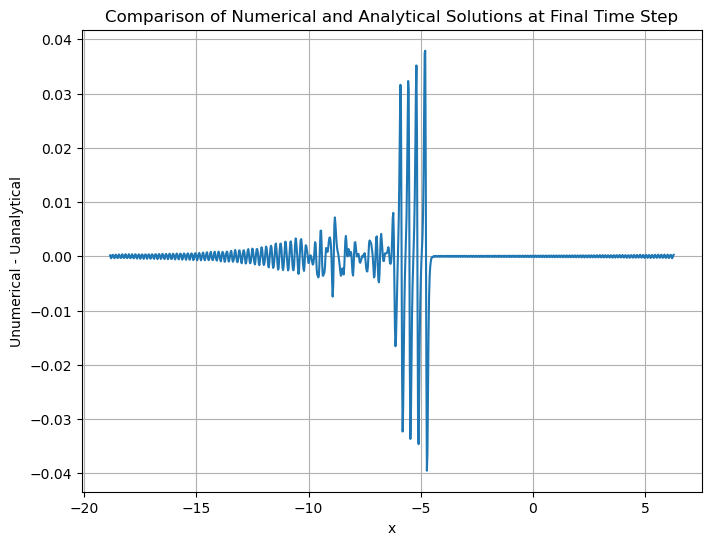

In [25]:
plt.figure(figsize=(8, 6))

time = 58

for i_analytical in range(len(analytical_time_array)):
    if abs(analytical_time_array[i_analytical] - time) < 1e-2:
        print(i_analytical)
        break
for i_numerical in range(len(numerical_time_array)):
    if abs(numerical_time_array[i_numerical] - time) < 1e-2:
        print(i_numerical)
        break

print(numerical_time_array[i_numerical], analytical_time_array[i_analytical])
plt.plot(xi, numerical_sol[i_numerical] - analytical_sol[i_analytical], label="Difference between numerical and analytical solutions")
plt.xlabel("x")
plt.ylabel("Unumerical - Uanalytical")
plt.grid()
plt.title("Comparison of Numerical and Analytical Solutions at Final Time Step")

## Validating the simulation

## Visualisation

### 2D Plot of U & X at some time

In [ ]:
print("Plotting.")
# ---Display the final solution at the last time step---
for i in range(len(time_array)):
    if abs(time_array[i] - 60) < 1e-2:
        print(i)
        break
plt.figure(figsize=(6,5))
plt.plot(xi, sol[i], label=f"t = {time_array[i]:.2f} TU")
plt.axvline(vd_norm * time_array[i] , color='red', linestyle='--', label="Debris position")
plt.xlabel("x")
plt.ylabel("U")
plt.ylim(-1.5,3)
plt.legend()
plt.grid()
plt.show()

### 3D Surface Plot of U, X, & T

In [ ]:
%matplotlib inline
import matplotlib.pyplot as plt

Xi, Tau = np.meshgrid(xi, time_array)  # Create meshgrid for plotting
fig = plt.figure(figsize=(6,5))
ax = plt.subplot(111, projection='3d')
surf = ax.plot_surface(Xi, Tau, sol, rstride=1000, cstride=1000, cmap='viridis', linewidth=0.1,antialiased=True)

ax.set_xlabel('x axis')
ax.set_ylabel('t axis')
ax.set_zlabel('U axis')

ax.view_init(elev=23, azim=100, roll=0)

plt.show()